In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import uproot

In [35]:
def calc_hist(vals, bins):    
    weights = np.ones(vals.shape)
    hist, bins = np.histogram(vals, bins=bins, weights=weights)
    digits = np.digitize(vals, bins)
    errs = np.asarray([np.linalg.norm(weights[digits==i]) for i in range(1, len(bins))])
    for i in range(1, len(bins)):
        hist[i-1] /= (bins[i] - bins[i-1])
        errs[i-1] /= (bins[i] - bins[i-1])
    return np.array([hist, errs])

In [3]:
observables = ['evid','xsec','pt']
files = ['/gpfs/gibbs/project/havener/ys668/other_output/omega_spectrum/pythia_default_15pthat20_omega.txt',\
        '/gpfs/gibbs/project/havener/ys668/other_output/omega_spectrum/pythia_default_20pthat25_omega.txt',\
        '/gpfs/gibbs/project/havener/ys668/other_output/omega_spectrum/pythia_default_25pthat30_omega.txt',\
        '/gpfs/gibbs/project/havener/ys668/other_output/omega_spectrum/pythia_default_30pthat35_omega.txt',\
        '/gpfs/gibbs/project/havener/ys668/other_output/omega_spectrum/pythia_default_35pthat40_omega.txt',\
        '/gpfs/gibbs/project/havener/ys668/other_output/omega_spectrum/pythia_default_40pthat45_omega.txt',\
        '/gpfs/gibbs/project/havener/ys668/other_output/omega_spectrum/pythia_default_45pthat50_omega.txt',\
        '/gpfs/gibbs/project/havener/ys668/other_output/omega_spectrum/pythia_default_50pthat1000_omega.txt']

In [4]:
df_array = []
for file in files:
    df = pd.read_csv(file, names=observables, low_memory=False)
    w = (float)(df.iloc[df.shape[0]-1]['xsec'])/200000
    df['w'] = np.ones(df.shape[0])*w
    df_array.append(df)
df = pd.concat([df for df in df_array])

In [7]:
observables = ['evid','xsec','pt']
files = ['/gpfs/gibbs/project/havener/ys668/other_output/omega_spectrum/herwig_15pthat20_omega.txt',\
        '/gpfs/gibbs/project/havener/ys668/other_output/omega_spectrum/herwig_20pthat25_omega.txt',\
        '/gpfs/gibbs/project/havener/ys668/other_output/omega_spectrum/herwig_25pthat30_omega.txt',\
        '/gpfs/gibbs/project/havener/ys668/other_output/omega_spectrum/herwig_30pthat35_omega.txt',\
        '/gpfs/gibbs/project/havener/ys668/other_output/omega_spectrum/herwig_35pthat40_omega.txt',\
        '/gpfs/gibbs/project/havener/ys668/other_output/omega_spectrum/herwig_40pthat45_omega.txt',\
        '/gpfs/gibbs/project/havener/ys668/other_output/omega_spectrum/herwig_45pthat50_omega.txt',\
        '/gpfs/gibbs/project/havener/ys668/other_output/omega_spectrum/herwig_50pthat1000_omega.txt']

In [8]:
df_array = []
for file in files:
    df_herwig = pd.read_csv(file, names=observables, low_memory=False)
    w = (float)(df_herwig.iloc[df_herwig.shape[0]-1]['xsec'])/200000
    df_herwig['w'] = np.ones(df_herwig.shape[0])*w
    df_array.append(df_herwig)
df_herwig = pd.concat([df_herwig for df_herwig in df_array])

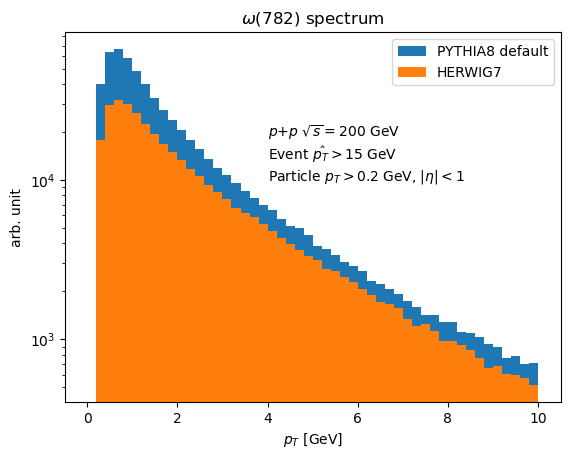

In [56]:
plt.hist(df['pt'], weights=df['w'], bins=np.arange(0,10.2,0.2), label='PYTHIA8 default')
plt.hist(df_herwig['pt'], weights=df_herwig['w'], bins=np.arange(0,10.2,0.2), label='HERWIG7')
plt.text(4, 1e4, '$p$+$p$ $\sqrt{s}=200$ GeV\nEvent $\hat{p_T}>15$ GeV\nParticle $p_T>0.2$ GeV, $|\eta|<1$')
plt.title('$\omega(782)$ spectrum')
plt.xlabel('$p_T$ [GeV]')
plt.ylabel('arb. unit')
plt.yscale('log')
plt.legend()

In [43]:
ptbins = np.concatenate([np.arange(0.2, 5.2, 0.25), np.arange(5.2, 12.2, 0.5)])
x = []
for i in range(0, len(ptbins)-1):
    x.append(0.5*(ptbins[i]+ptbins[i+1]))
x = np.array(x)

In [57]:
w_array = np.unique(df['w'])
dndpt_over_nevt_avg = np.zeros(len(ptbins)-1)
dndpt_over_nevt_variance = np.zeros(len(ptbins)-1)
for i in range(0, len(w_array)):
    dndpt_over_nevt, dndpt_over_nevt_err = calc_hist(df[df.w == w_array[i]]['pt'], ptbins)/200000
    # N(omega, pthat bin i) / N(omega), i.e., probability of finding an omega to come from the pthat bin i
    # w = sum(df[df.w == w_array[i]]['w'])/sum(df['w'])
    # N(evt, pthat bin i) / N(evt). This is the correct weight to use here, since dndpt_over_nevt is already per-event
    w = w_array[i]/sum(w_array)
    dndpt_over_nevt_avg += w*dndpt_over_nevt
    dndpt_over_nevt_variance += w**2*dndpt_over_nevt_err**2

In [60]:
w_array = np.unique(df_herwig['w'])
dndpt_over_nevt_avg_herwig = np.zeros(len(ptbins)-1)
dndpt_over_nevt_variance_herwig = np.zeros(len(ptbins)-1)
for i in range(0, len(w_array)):
    dndpt_over_nevt, dndpt_over_nevt_err = calc_hist(df_herwig[df_herwig.w == w_array[i]]['pt'], ptbins)/200000
    w = w_array[i]/sum(w_array)
    dndpt_over_nevt_avg_herwig += w*dndpt_over_nevt
    dndpt_over_nevt_variance_herwig += w**2*dndpt_over_nevt_err**2

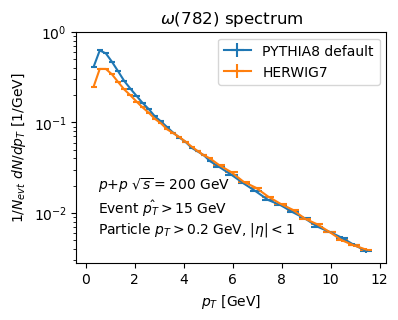

In [61]:
plt.figure(figsize=(4,3))
plt.errorbar(x, dndpt_over_nevt_avg, xerr=x-ptbins[:-1], yerr=np.sqrt(dndpt_over_nevt_variance), label='PYTHIA8 default')
plt.errorbar(x, dndpt_over_nevt_avg_herwig, xerr=x-ptbins[:-1], yerr=np.sqrt(dndpt_over_nevt_variance_herwig), label='HERWIG7')
plt.text(0.5, 0.006, '$p$+$p$ $\sqrt{s}=200$ GeV\nEvent $\hat{p_T}>15$ GeV\nParticle $p_T>0.2$ GeV, $|\eta|<1$')
plt.title('$\omega(782)$ spectrum')
plt.xlabel('$p_T$ [GeV]')
plt.ylabel('$1/{N_{evt}}$ $dN/dp_T$ [$1/$GeV]')
plt.yscale('log')
plt.ylim(top=1)
plt.legend()